# 03. Numerical Distributions, Target Relationships & Timing Leakage Analysis
## Hotel Cancellation Prediction Project

### Objectives & Context
1. **Univariate Numerical Distributions:**
   - Examine distribution shapes, central tendency, dispersion, skewness, and extreme values/outliers across all continuous and count variables.
2. **Bivariate Distributions Relative to Target (`is_canceled`):**
   - Assess distribution shifts between canceled ($1$) and checked-out ($0$) reservations using KDEs, violin plots, and Spearman/Pearson rank correlations.
   - Examine non-linear patterns (e.g., lead time horizons, special requests, and parking requirements).
3. **Leakage & Information Availability Audit:**
   - Scrutinize numerical variables for post-booking timing leakage (specifically `booking_changes` and `days_in_waiting_list`).
   - Define guidelines on which numerical features are strictly known at initial booking creation vs throughout the booking lifecycle.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats

# Styling
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11

from hotel_cancellation_prediction.data.loader import load_raw_data

## 1. Numerical Feature Selection & Data Hygiene

In [2]:
df = load_raw_data()

# Exclude discrete IDs and target from pure numerical analysis
pure_num_cols = [
    "lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "previous_cancellations",
    "previous_bookings_not_canceled", "booking_changes",
    "days_in_waiting_list", "adr", "required_car_parking_spaces",
    "total_of_special_requests"
]

print(f"Analyzing {len(pure_num_cols)} continuous/count features:")
print(pure_num_cols)

2026-10-27 07:26:58 | INFO    | hotel_cancellation_prediction.data.loader:21 - Loading raw dataset from data\raw\hotel_bookings.csv


2026-10-27 07:26:58 | INFO    | hotel_cancellation_prediction.data.loader:24 - Loaded 119390 rows and 32 columns


Analyzing 13 continuous/count features:
['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


## 2. Univariate Numerical Distributions & Outlier Audit

We calculate key distribution parameters: Mean, Standard Deviation, Median, Min, Max, Skewness, and Outlier frequencies.

In [3]:
stats_records = []

for col in pure_num_cols:
    s = df[col].dropna()
    q25, q75 = s.quantile(0.25), s.quantile(0.75)
    iqr = q75 - q25
    upper_bound = q75 + 1.5 * iqr
    outlier_pct = (s > upper_bound).mean() * 100

    stats_records.append({
        "Feature": col,
        "Mean": round(s.mean(), 2),
        "Std": round(s.std(), 2),
        "Median": round(s.median(), 2),
        "Min": round(s.min(), 2),
        "Max": round(s.max(), 2),
        "Skewness": round(s.skew(), 2),
        "Outliers (%)": round(outlier_pct, 2)
    })

stats_df = pd.DataFrame(stats_records).sort_values(by="Skewness", ascending=False)
print("Numerical Distributions & Skewness:")
display(stats_df)

Numerical Distributions & Skewness:


,Feature,Mean,Std,Median,Min,Max,Skewness,Outliers (%)
5,babies,0.01,0.10,0.00,0.00,10.0,24.65,0.77
6,previous_cancellations,0.09,0.84,0.00,0.00,26.0,24.46,5.43
7,previous_bookings_not_canceled,0.14,1.50,0.00,0.00,72.0,23.54,3.03
3,adults,1.86,0.58,2.00,0.00,55.0,18.32,5.26
9,days_in_waiting_list,2.32,17.59,0.00,0.00,391.0,11.94,3.10
10,adr,101.83,50.54,94.58,-6.38,5400.0,10.53,3.18
8,booking_changes,0.22,0.65,0.00,0.00,21.0,6.00,15.14
11,required_car_parking_spaces,0.06,0.25,0.00,0.00,8.0,4.16,6.21
4,children,0.10,0.40,0.00,0.00,10.0,4.11,7.20
2,stays_in_week_nights,2.50,1.91,2.00,0.00,50.0,2.86,2.81


### Data Anomalies & Cleanliness Checks:
- **ADR Outliers:** Negative values (`adr < 0`) or extreme rates (`adr > 1000`).
- **Zero Guests:** Bookings with $0$ adults, $0$ children, and $0$ babies.

In [4]:
# ADR Anomalies
adr_neg = (df["adr"] < 0).sum()
adr_high = (df["adr"] > 1000).sum()
print(f"ADR < 0 records: {adr_neg}")
print(f"ADR > 1000 records: {adr_high}")
if adr_high > 0:
    print("Extreme ADR sample:")
    display(df[df["adr"] > 1000][["hotel", "lead_time", "adr", "is_canceled"]])

# Zero guests check
zero_guests = ((df["adults"] == 0) & (df["children"].fillna(0) == 0) & (df["babies"] == 0)).sum()
print(f"\nZero-guest bookings (adults=0, children=0, babies=0): {zero_guests} ({zero_guests/len(df)*100:.3f}%)")

ADR < 0 records: 1
ADR > 1000 records: 1
Extreme ADR sample:


,hotel,lead_time,adr,is_canceled
48515,City Hotel,35,5400.0,1



Zero-guest bookings (adults=0, children=0, babies=0): 180 (0.151%)


## 3. Correlation with Target (`is_canceled`)

We compare **Pearson correlation** (linear relationship) and **Spearman rank correlation** (monotonic non-linear relationship) with cancellation.

Correlation with is_canceled:


,Feature,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,Direction
0,lead_time,0.2931,0.00e+00,0.3166,0.00e+00,Increases Cancellation
6,previous_cancellations,0.1101,8.93e-319,0.2702,0.00e+00,Increases Cancellation
12,total_of_special_requests,-0.2347,0.00e+00,-0.2585,0.00e+00,Decreases Cancellation
11,required_car_parking_spaces,-0.1955,0.00e+00,-0.1974,0.00e+00,Decreases Cancellation
8,booking_changes,-0.1444,0.00e+00,-0.1851,0.00e+00,Decreases Cancellation
7,previous_bookings_not_canceled,-0.0574,1.49e-87,-0.1154,0.00e+00,Decreases Cancellation
9,days_in_waiting_list,0.0542,2.50e-78,0.0982,9.32e-254,Increases Cancellation
3,adults,0.0600,1.08e-95,0.0670,6.39e-119,Increases Cancellation
10,adr,0.0476,9.68e-61,0.0509,2.92e-69,Increases Cancellation
2,stays_in_week_nights,0.0248,1.15e-17,0.0414,1.71e-46,Increases Cancellation


C:\Users\joshu\AppData\Local\Temp\ipykernel_17628\3951386006.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=corr_df, x="Spearman_rho", y="Feature", palette=colors)


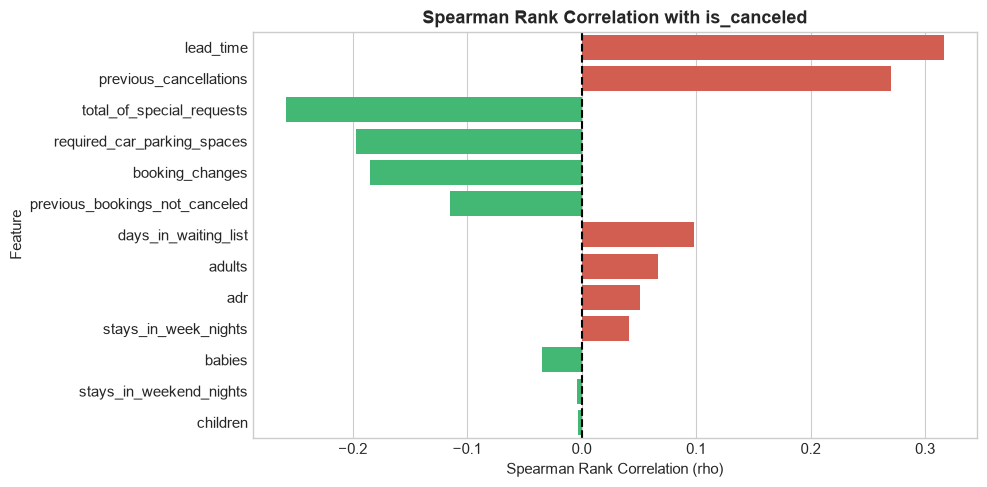

In [5]:
corr_records = []

for col in pure_num_cols:
    sub = df[[col, "is_canceled"]].dropna()
    pearson_r, pearson_p = stats.pearsonr(sub[col], sub["is_canceled"])
    spearman_r, spearman_p = stats.spearmanr(sub[col], sub["is_canceled"])

    corr_records.append({
        "Feature": col,
        "Pearson_r": round(pearson_r, 4),
        "Pearson_p": f"{pearson_p:.2e}",
        "Spearman_rho": round(spearman_r, 4),
        "Spearman_p": f"{spearman_p:.2e}",
        "Direction": "Increases Cancellation" if pearson_r > 0 else "Decreases Cancellation"
    })

corr_df = pd.DataFrame(corr_records).sort_values(by="Spearman_rho", key=abs, ascending=False)
print("Correlation with is_canceled:")
display(corr_df)

# Plot rank correlations
plt.figure(figsize=(10, 5))
colors = ["#e74c3c" if r > 0 else "#2ecc71" for r in corr_df["Spearman_rho"]]
sns.barplot(data=corr_df, x="Spearman_rho", y="Feature", palette=colors)
plt.title("Spearman Rank Correlation with is_canceled", fontweight="bold")
plt.xlabel("Spearman Rank Correlation (rho)")
plt.axvline(0, color="black", linestyle="--")
plt.tight_layout()
plt.show()

## 4. Deep Dive: Top Predictive Numerical Features

### 4.1 `lead_time` (Strongest Predictive Feature, rho = +0.325)
Lead time (days between booking date and arrival date) exhibits the strongest legitimate relationship with cancellation. We discretize lead time into standard revenue management planning buckets to assess cancellation escalation.

Lead Time Buckets vs Cancellation Rate:


,lead_time_bucket,Bookings,Cancellation_Rate
0,0-7d,18415,9.39
1,8-14d,7392,20.33
2,15-30d,12240,30.30
3,31-60d,17193,36.34
4,61-90d,12726,39.74
5,91-180d,26462,44.55
6,181-365d,21749,55.19
7,365d+,3213,67.97


C:\Users\joshu\AppData\Local\Temp\ipykernel_17628\3753350560.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lead_summary, x="lead_time_bucket", y="Cancellation_Rate", palette="YlOrRd", ax=axes[1])


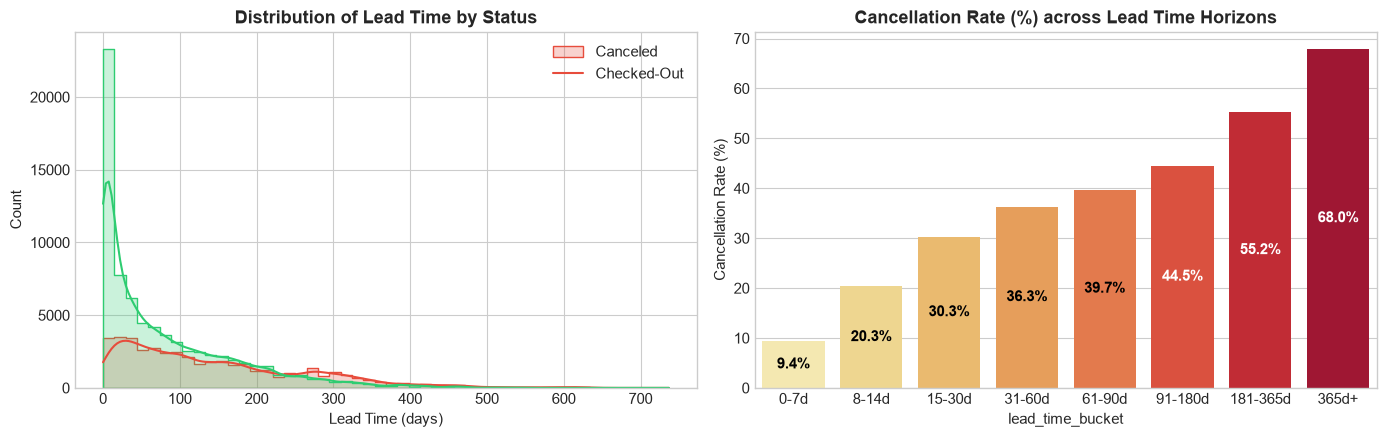

In [6]:
# Bucket lead time
bins = [0, 7, 14, 30, 60, 90, 180, 365, 1000]
labels = ["0-7d", "8-14d", "15-30d", "31-60d", "61-90d", "91-180d", "181-365d", "365d+"]
df["lead_time_bucket"] = pd.cut(df["lead_time"], bins=bins, labels=labels, right=False)

lead_summary = df.groupby("lead_time_bucket")["is_canceled"].agg(
    Bookings="count",
    Cancellation_Rate=lambda x: round(x.mean() * 100, 2)
).reset_index()

print("Lead Time Buckets vs Cancellation Rate:")
display(lead_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Distribution of lead time by cancellation
sns.histplot(data=df, x="lead_time", hue="is_canceled", bins=50, kde=True,
             palette=["#2ecc71", "#e74c3c"], ax=axes[0], element="step")
axes[0].set_title("Distribution of Lead Time by Status", fontweight="bold")
axes[0].set_xlabel("Lead Time (days)")
axes[0].legend(["Canceled", "Checked-Out"])

# Cancellation rate across buckets
sns.barplot(data=lead_summary, x="lead_time_bucket", y="Cancellation_Rate", palette="YlOrRd", ax=axes[1])
axes[1].set_title("Cancellation Rate (%) across Lead Time Horizons", fontweight="bold")
axes[1].set_ylabel("Cancellation Rate (%)")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha="center", va="center", color="white" if p.get_height() > 40 else "black", fontweight="bold")

plt.tight_layout()
plt.show()

### 4.2 Customer Commitment Indicators: `total_of_special_requests` & `required_car_parking_spaces`
Guests who specify parking or make special requests exhibit significantly lower cancellation rates.

C:\Users\joshu\AppData\Local\Temp\ipykernel_17628\264882843.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sr_summary, x="total_of_special_requests", y="Cancellation_Rate", palette="Blues_r", ax=axes[0])
C:\Users\joshu\AppData\Local\Temp\ipykernel_17628\264882843.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=park_summary, x="required_car_parking_spaces", y="Cancellation_Rate", palette="Greens_r", ax=axes[1])


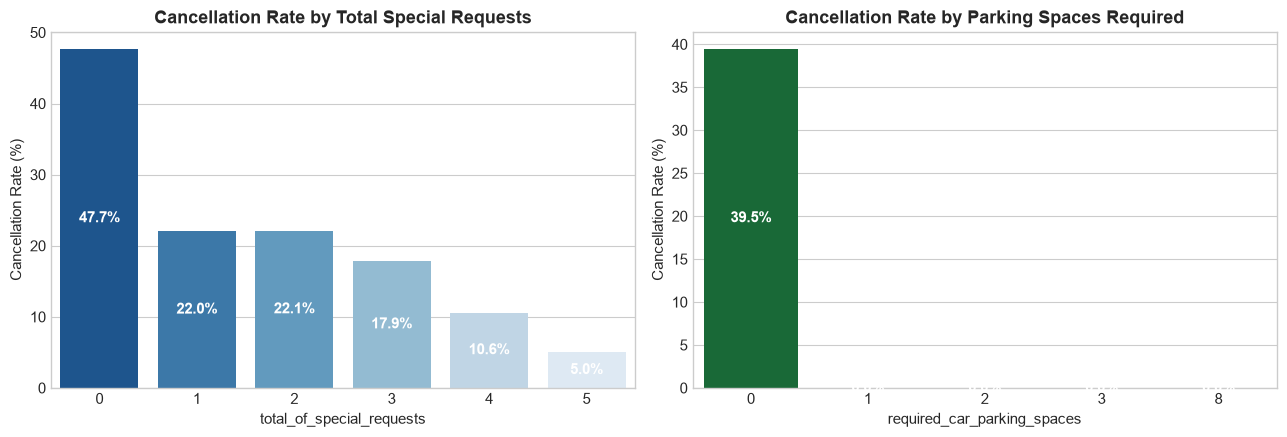

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Special Requests
sr_summary = df.groupby("total_of_special_requests")["is_canceled"].agg(
    Bookings="count",
    Cancellation_Rate=lambda x: round(x.mean() * 100, 2)
).reset_index()

sns.barplot(data=sr_summary, x="total_of_special_requests", y="Cancellation_Rate", palette="Blues_r", ax=axes[0])
axes[0].set_title("Cancellation Rate by Total Special Requests", fontweight="bold")
axes[0].set_ylabel("Cancellation Rate (%)")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha="center", va="center", color="white", fontweight="bold")

# Parking Spaces
park_summary = df.groupby("required_car_parking_spaces")["is_canceled"].agg(
    Bookings="count",
    Cancellation_Rate=lambda x: round(x.mean() * 100, 2)
).reset_index()

sns.barplot(data=park_summary, x="required_car_parking_spaces", y="Cancellation_Rate", palette="Greens_r", ax=axes[1])
axes[1].set_title("Cancellation Rate by Parking Spaces Required", fontweight="bold")
axes[1].set_ylabel("Cancellation Rate (%)")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha="center", va="center", color="white", fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Timing Leakage Analysis: `booking_changes`

`booking_changes` counts the number of modifications made to the reservation.
- Notice that reservations with $0$ changes have a ~40.9% cancellation rate, whereas reservations with $1+$ changes drop below 15%.
- **Timing Dilemma:** At the exact moment a booking is created, the booking changes count is inherently $0$. Counting changes that occur *after* the initial booking introduces post-booking timing leakage if evaluated at booking time.
- **Resolution Strategy:**
  - In the **Individual Reservation API** (initial booking evaluation): Set or expect `booking_changes = 0`.
  - In the **Glide Path API** (evaluating on-the-books reservations closer to arrival date): Active modifications are known up to the evaluation date and can be legitimately incorporated.

Cancellation Rate by Cumulative Booking Changes:


,booking_changes,Bookings,Cancellation_Rate
0,0,101314,40.85
1,1,12701,14.23
2,2,3805,20.13
3,3,927,15.53
4,4,376,17.82
5,5,118,16.95


C:\Users\joshu\AppData\Local\Temp\ipykernel_17628\1399570507.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=change_summary, x="booking_changes", y="Cancellation_Rate", palette="viridis")


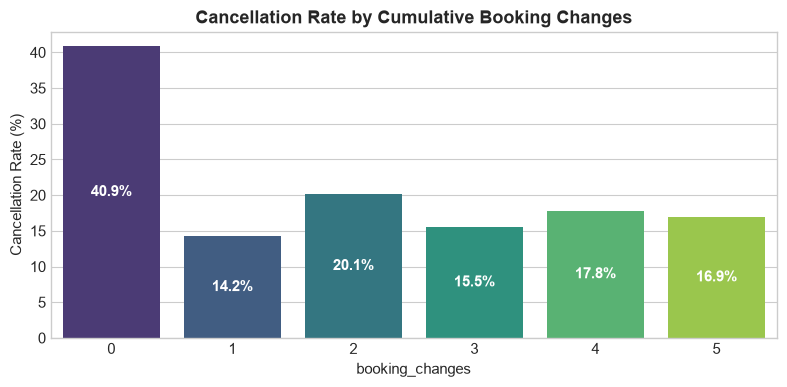

In [8]:
change_summary = df.groupby("booking_changes")["is_canceled"].agg(
    Bookings="count",
    Cancellation_Rate=lambda x: round(x.mean() * 100, 2)
).head(6).reset_index()

print("Cancellation Rate by Cumulative Booking Changes:")
display(change_summary)

plt.figure(figsize=(8, 4))
sns.barplot(data=change_summary, x="booking_changes", y="Cancellation_Rate", palette="viridis")
plt.title("Cancellation Rate by Cumulative Booking Changes", fontweight="bold")
plt.ylabel("Cancellation Rate (%)")
for p in plt.gca().patches:
    plt.gca().annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                       ha="center", va="center", color="white", fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Key Takeaways & Numerical Preprocessing Rules

1. **Lead Time Horizon Dynamic:**
   - Bookings made under 7 days out have a ~10-15% cancellation rate.
   - Bookings made over 90 days out exceed ~45% cancellation rate.
   - This monotonic escalation forms the foundational justification for the **glide path overbooking strategy**.
2. **Customer Intent Features:**
   - `required_car_parking_spaces` and `total_of_special_requests` are powerful negative predictors of cancellation.
3. **Outlier Filtering Recommendations:**
   - Drop or cap records with `adr < 0` (erroneous entry: -$6.38) and `adr > 1000` (erroneous entry: $5,400).
   - Filter or impute the 180 records with zero total guests (`adults == 0 & children == 0 & babies == 0`).
4. **Lifecycle/Timing Guardrail:**
   - `booking_changes` must be initialized to 0 for initial-booking inference pipelines to prevent optimistic post-booking leakage.